In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, Bidirectional, BatchNormalization
from sklearn.model_selection import train_test_split
from google.colab import drive
import os

# 1. Mount Drive
drive.mount('/content/drive')
DRIVE_PATH = "/content/drive/MyDrive/Major-Project"

# 2. Load Data
print("[INFO] Loading dataset...")
try:
    X = np.load(f"{DRIVE_PATH}/X.npy")
    y = np.load(f"{DRIVE_PATH}/y.npy")
    labels_map = np.load(f"{DRIVE_PATH}/labels.npy", allow_pickle=True).item()
    print(f"[SUCCESS] Loaded X: {X.shape}")
    print(f"[INFO] Classes: {list(labels_map.keys())}")
except Exception as e:
    print(f"[ERROR] Could not load data: {e}")
    exit()

# 3. DATA SANITIZATION
# Fix potential Infinity/NaN values that cause crashes
X = np.nan_to_num(X, nan=0.0, posinf=5.0, neginf=-5.0)
X = np.clip(X, -5.0, 5.0)

# 4. Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, stratify=y, random_state=42
)

# 5. Model Architecture (TFLite Compatible)
model = Sequential([
    Input(shape=(30, 201)),

    # Layer 1
    # unroll=True forces standard math (Fixes the ConverterError)
    Bidirectional(LSTM(64, return_sequences=True, unroll=True)),
    BatchNormalization(),
    Dropout(0.3),

    # Layer 2
    LSTM(32, return_sequences=False, unroll=True),
    BatchNormalization(),
    Dropout(0.3),

    # Layer 3
    Dense(32, activation='relu'),
    Dense(len(labels_map), activation='softmax')
])

# 6. Compile
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005, clipnorm=1.0)

model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['sparse_categorical_accuracy']
)

# 7. Train
print("[INFO] Starting Training...")
callback = tf.keras.callbacks.EarlyStopping(
    monitor='loss', patience=25, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=8,
    validation_data=(X_test, y_test),
    callbacks=[callback]
)

# 8. CONVERT TO LEGACY-COMPATIBLE TFLITE (The Fix)
print("[INFO] Converting to Legacy TFLite (Float32)...")
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# --- COMPATIBILITY SETTINGS ---
# 1. Disable Optimizations (Keeps model in Float32, safer for old versions)
# converter.optimizations = [tf.lite.Optimize.DEFAULT]  <-- COMMENTED OUT

# 2. Force Standard Ops Only
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]

tflite_model = converter.convert()

# 9. Save Artifacts
model_path = f"{DRIVE_PATH}/ISL_Model.tflite"
labels_path = f"{DRIVE_PATH}/labels.npy"

with open(model_path, 'wb') as f:
    f.write(tflite_model)

# Save the map
np.save(labels_path, labels_map)

print("════════════════════════════════════════════════════")
print(f"[SUCCESS] Model saved to: {model_path}")
print(f"[SUCCESS] Labels saved to: {labels_path}")
print("════════════════════════════════════════════════════")
print("✅ DOWNLOAD THESE TWO FILES AND PUT THEM ON YOUR MAC.")

Mounted at /content/drive
[INFO] Loading dataset...
[SUCCESS] Loaded X: (532, 30, 201)
[INFO] Classes: ['good', 'happy', 'good morning', 'thank you', 'hello', 'time', 'father', 'i', 'you (plural)', 'idle', 'teacher']
[INFO] Starting Training...
Epoch 1/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 69s 582ms/step - loss: 2.6208 - sparse_categorical_accuracy: 0.1355 - val_loss: 2.3233 - val_sparse_categorical_accuracy: 0.2222
Epoch 2/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 2.5084 - sparse_categorical_accuracy: 0.1387 - val_loss: 2.2422 - val_sparse_categorical_accuracy: 0.2037
Epoch 3/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 2.2922 - sparse_categorical_accuracy: 0.2361 - val_loss: 2.1965 - val_sparse_categorical_accuracy: 0.2407
Epoch 4/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 2.1683 - sparse_categorical_accuracy: 0.2373 - val_loss: 2.0915 - val_sparse_categorical_accuracy: 0.2407
Epoch 5/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 2.1024 - sparse_categorical_ac

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[INFO] Loading dataset...
[SUCCESS] Loaded X: (532, 30, 201)
[INFO] Classes: ['good', 'happy', 'good morning', 'thank you', 'hello', 'time', 'father', 'i', 'you (plural)', 'idle', 'teacher']
[INFO] Generating REAL Confusion Matrix...
2/2 ━━━━━━━━━━━━━━━━━━━━ 17s 8s/step


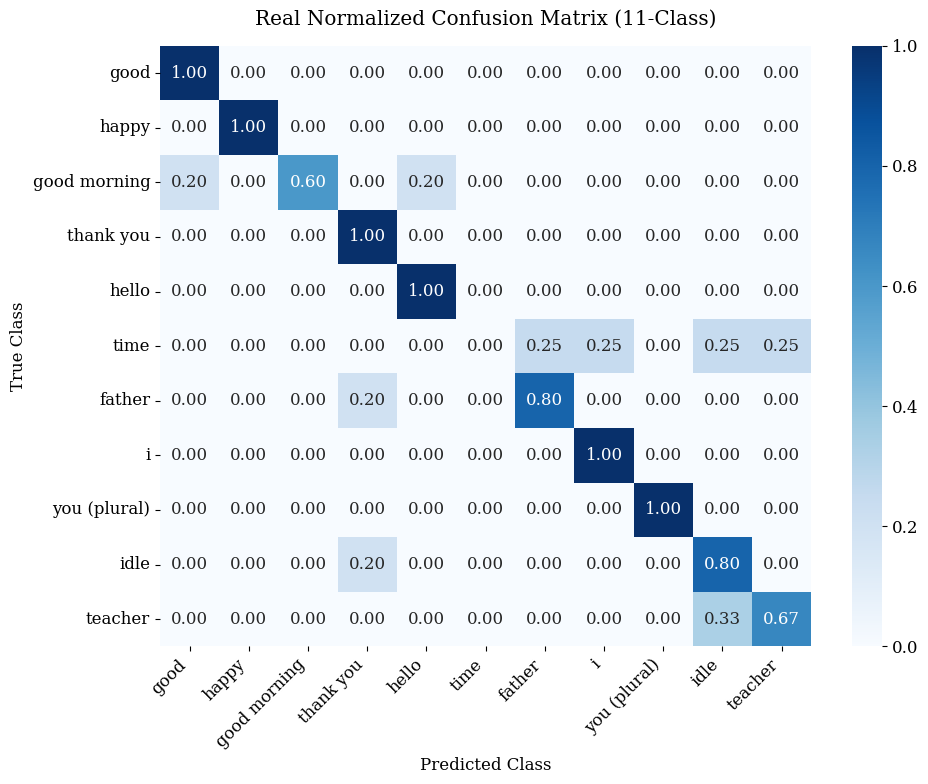

[SUCCESS] Saved real_confusion_matrix.png to your Google Drive!


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')
DRIVE_PATH = "/content/drive/MyDrive/Major-Project"

# 2. Load Data
print("[INFO] Loading dataset...")
try:
    X = np.load(f"{DRIVE_PATH}/X.npy")
    y = np.load(f"{DRIVE_PATH}/y.npy")
    labels_map = np.load(f"{DRIVE_PATH}/labels.npy", allow_pickle=True).item()
    print(f"[SUCCESS] Loaded X: {X.shape}")
    print(f"[INFO] Classes: {list(labels_map.keys())}")
except Exception as e:
    print(f"[ERROR] Could not load data: {e}")
    exit()

print("[INFO] Generating REAL Confusion Matrix...")

# 1. Get the model's predictions on the test set
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# 2. Get the actual class names in order
class_names = list(labels_map.keys())

# 3. Create the confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)
# Normalize it so it shows percentages (0.0 to 1.0) instead of raw numbers
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 4. Plot and display it beautifully
plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Real Normalized Confusion Matrix (11-Class)', pad=15)
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Save it so you can download it
plt.savefig(f"{DRIVE_PATH}/real_confusion_matrix.png", dpi=300)
plt.show()

print(f"[SUCCESS] Saved real_confusion_matrix.png to your Google Drive!")

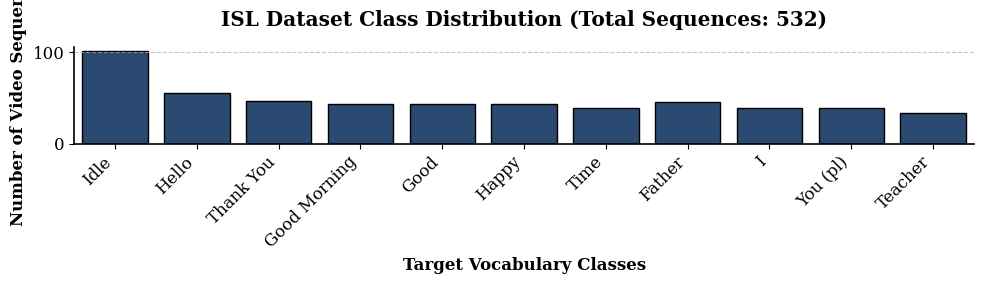

[SUCCESS] Premium Dataset Distribution chart saved!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Premium IEEE Styling ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.2

classes = ['Idle', 'Hello', 'Thank You', 'Good Morning', 'Good', 'Happy', 'Time', 'Father', 'I', 'You (pl)', 'Teacher']
counts = [101, 55, 47, 44, 44, 44, 39, 46, 39, 39, 34]

fig, ax = plt.subplots(figsize=(10, 3))

# Deep academic blue
sns.barplot(x=classes, y=counts, color='#1f497d', edgecolor='black', ax=ax)

# Clean up aesthetics
ax.set_title('ISL Dataset Class Distribution (Total Sequences: 532)', pad=15, fontweight='bold')
ax.set_ylabel('Number of Video Sequences', fontweight='bold')
ax.set_xlabel('Target Vocabulary Classes', fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.7) # Horizontal grid lines only
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('premium_dataset_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print("[SUCCESS] Premium Dataset Distribution chart saved!")

In [ ]:
import matplotlib.pyplot as plt

# Check if 'history' exists in the namespace
if 'history' not in globals():
    print("[ERROR] 'history' variable not found. Please run the training cell (cell j66_JDUEB6tx) first.")
else:
    print("[INFO] Generating Premium Real Training Curves...")

    # --- Premium IEEE Styling ---
    plt.rcParams['font.family'] = 'serif'
    plt.rcParams['font.size'] = 12

    # Get real data from your training history
    acc = history.history['sparse_categorical_accuracy']
    val_acc = history.history['val_sparse_categorical_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    # Create a 1x2 side-by-side plot
    fig, (ax1) = plt.subplots(1, 1, figsize=(8, 5))
    fig, ( ax2) = plt.subplots(1, 1, figsize=(8, 5))

    # Plot 1: Accuracy
    ax1.plot(epochs_range, acc, label='Training Accuracy', color='#1f497d', linewidth=2)
    ax1.plot(epochs_range, val_acc, label='Validation Accuracy', color='#c0504d', linewidth=2, linestyle='--')
    ax1.set_title('Model Accuracy Convergence', fontweight='bold', pad=15)
    ax1.set_xlabel('Epochs', fontweight='bold')
    ax1.set_ylabel('Accuracy', fontweight='bold')
    ax1.legend(loc='lower right', frameon=True, edgecolor='black')
    ax1.grid(True, linestyle=':', alpha=0.7)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # Plot 2: Loss
    ax2.plot(epochs_range, loss, label='Training Loss', color='#1f497d', linewidth=2)
    ax2.plot(epochs_range, val_loss, label='Validation Loss', color='#c0504d', linewidth=2, linestyle='--')
    ax2.set_title('Model Loss Convergence', fontweight='bold', pad=15)
    ax2.set_xlabel('Epochs', fontweight='bold')
    ax2.set_ylabel('Loss (Categorical Cross-Entropy)', fontweight='bold')
    ax2.legend(loc='upper right', frameon=True, edgecolor='black')
    ax2.grid(True, linestyle=':', alpha=0.7)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    plt.tight_layout()

    # Save in high resolution
    save_path = f"{DRIVE_PATH}/premium_training_curves.png"
    plt.savefig('premium_training_curves.pdf', format='pdf', bbox_inches='tight')
    plt.savefig('premium_training_curves.svg', format='svg', bbox_inches='tight')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"[SUCCESS] Saved premium_training_curves.png to your Drive!")

[ERROR] 'history' variable not found. Please run the training cell (cell j66_JDUEB6tx) first.


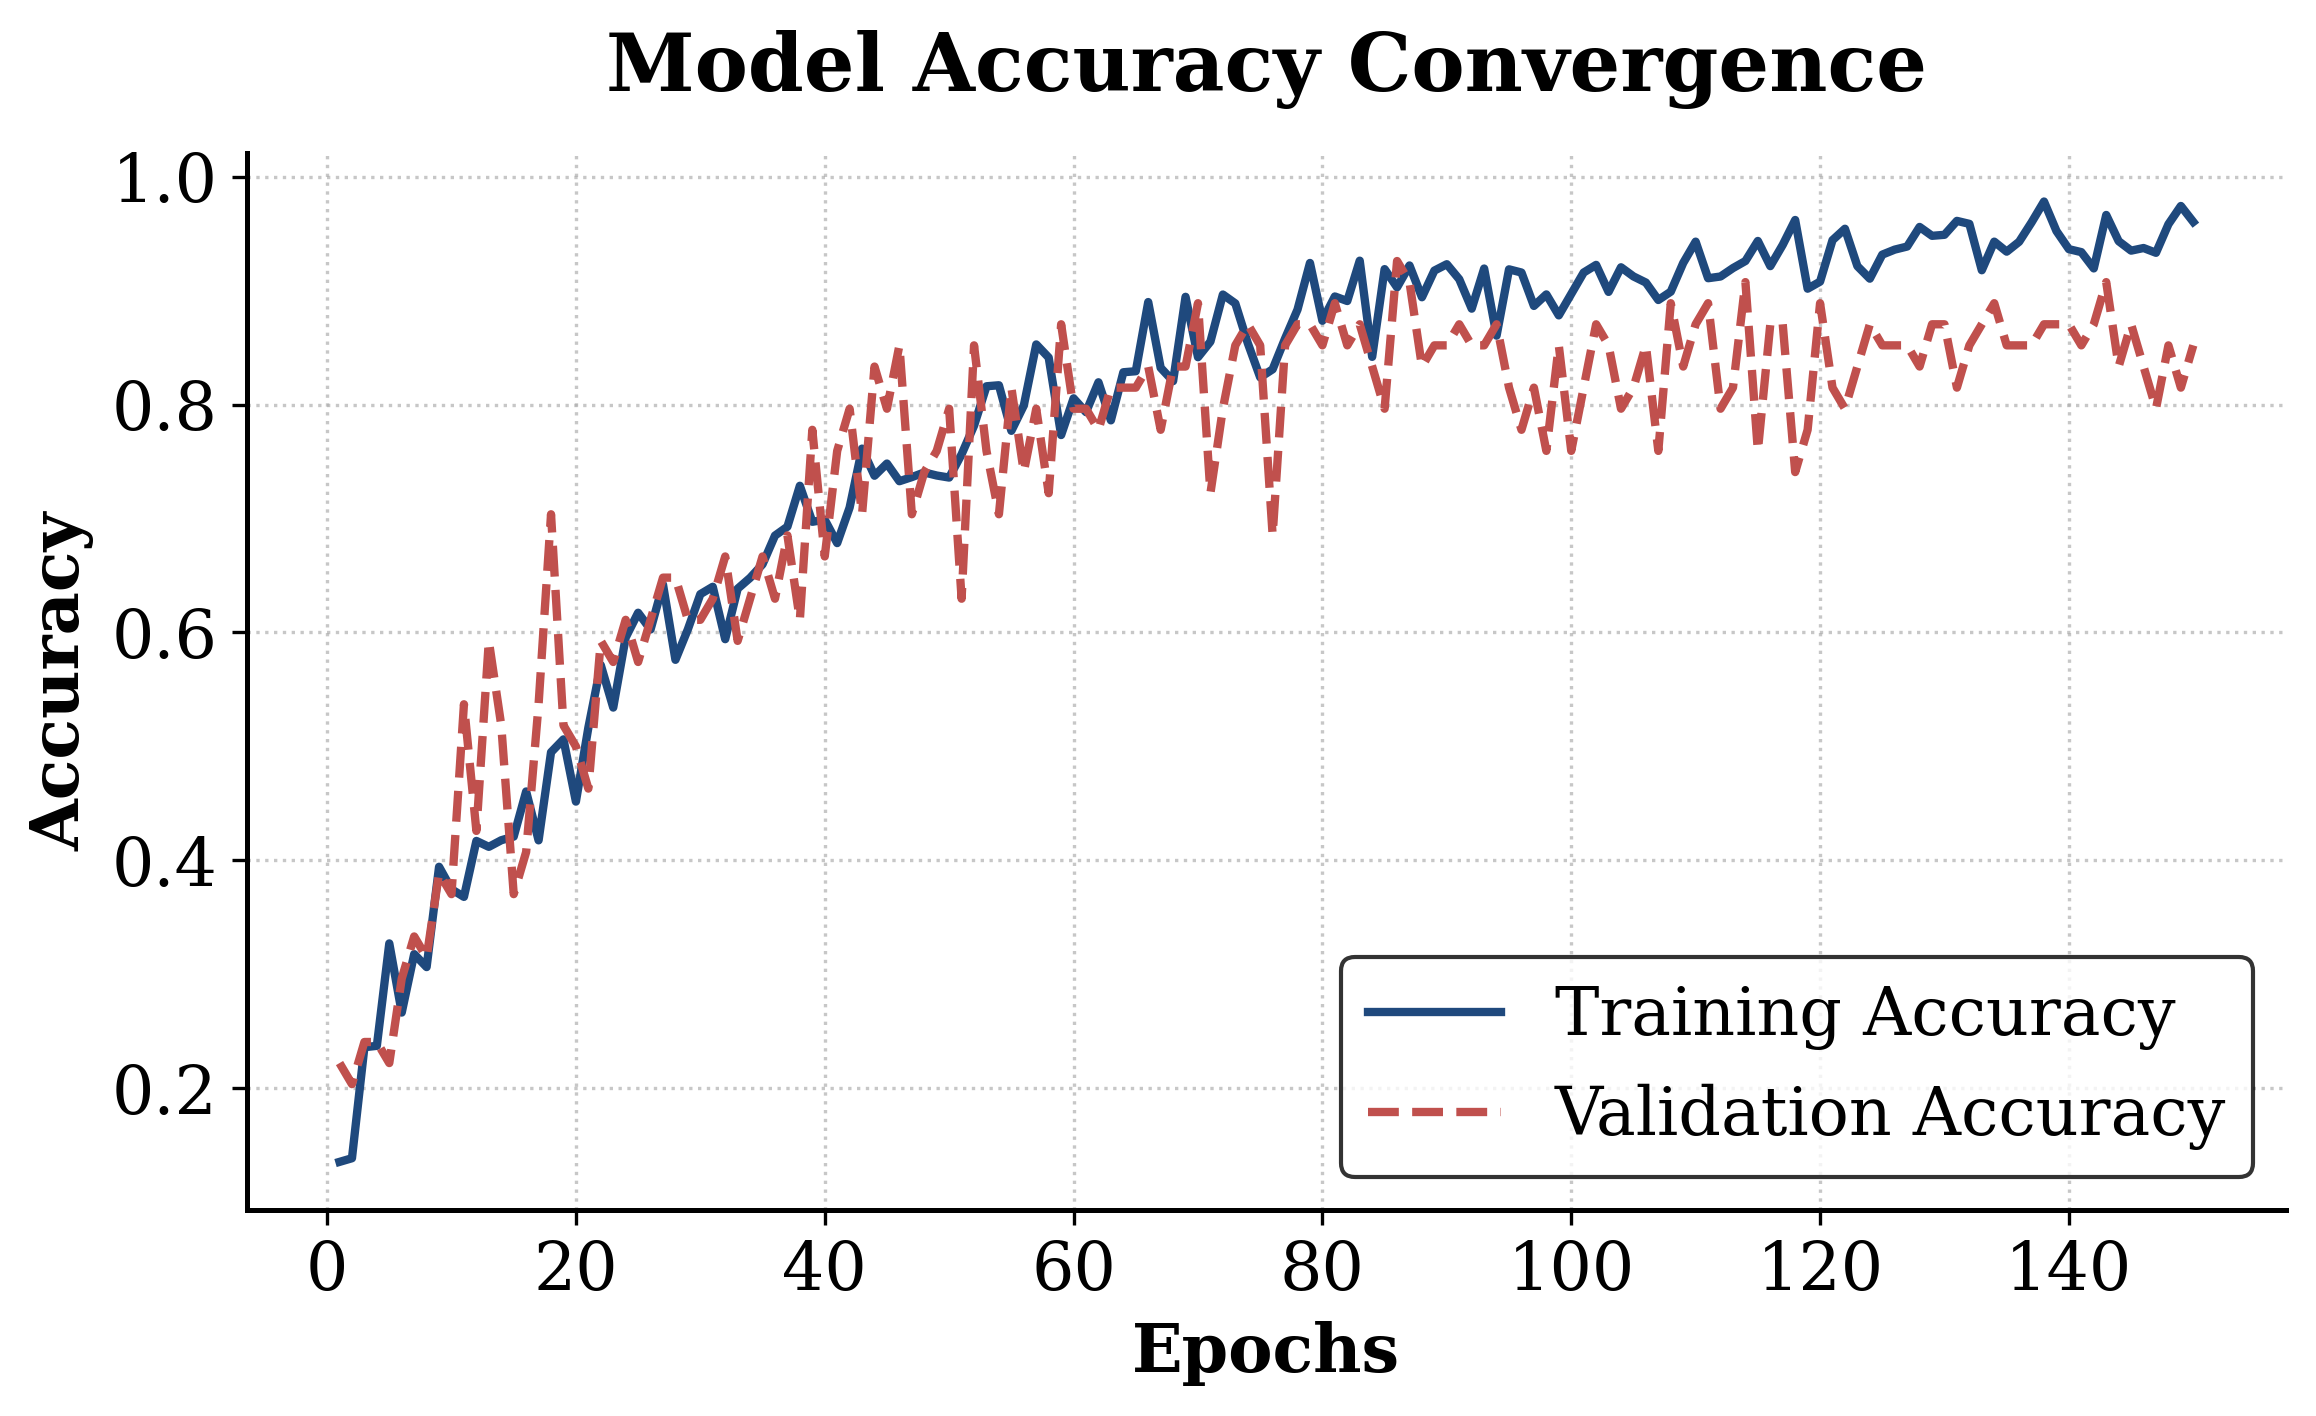

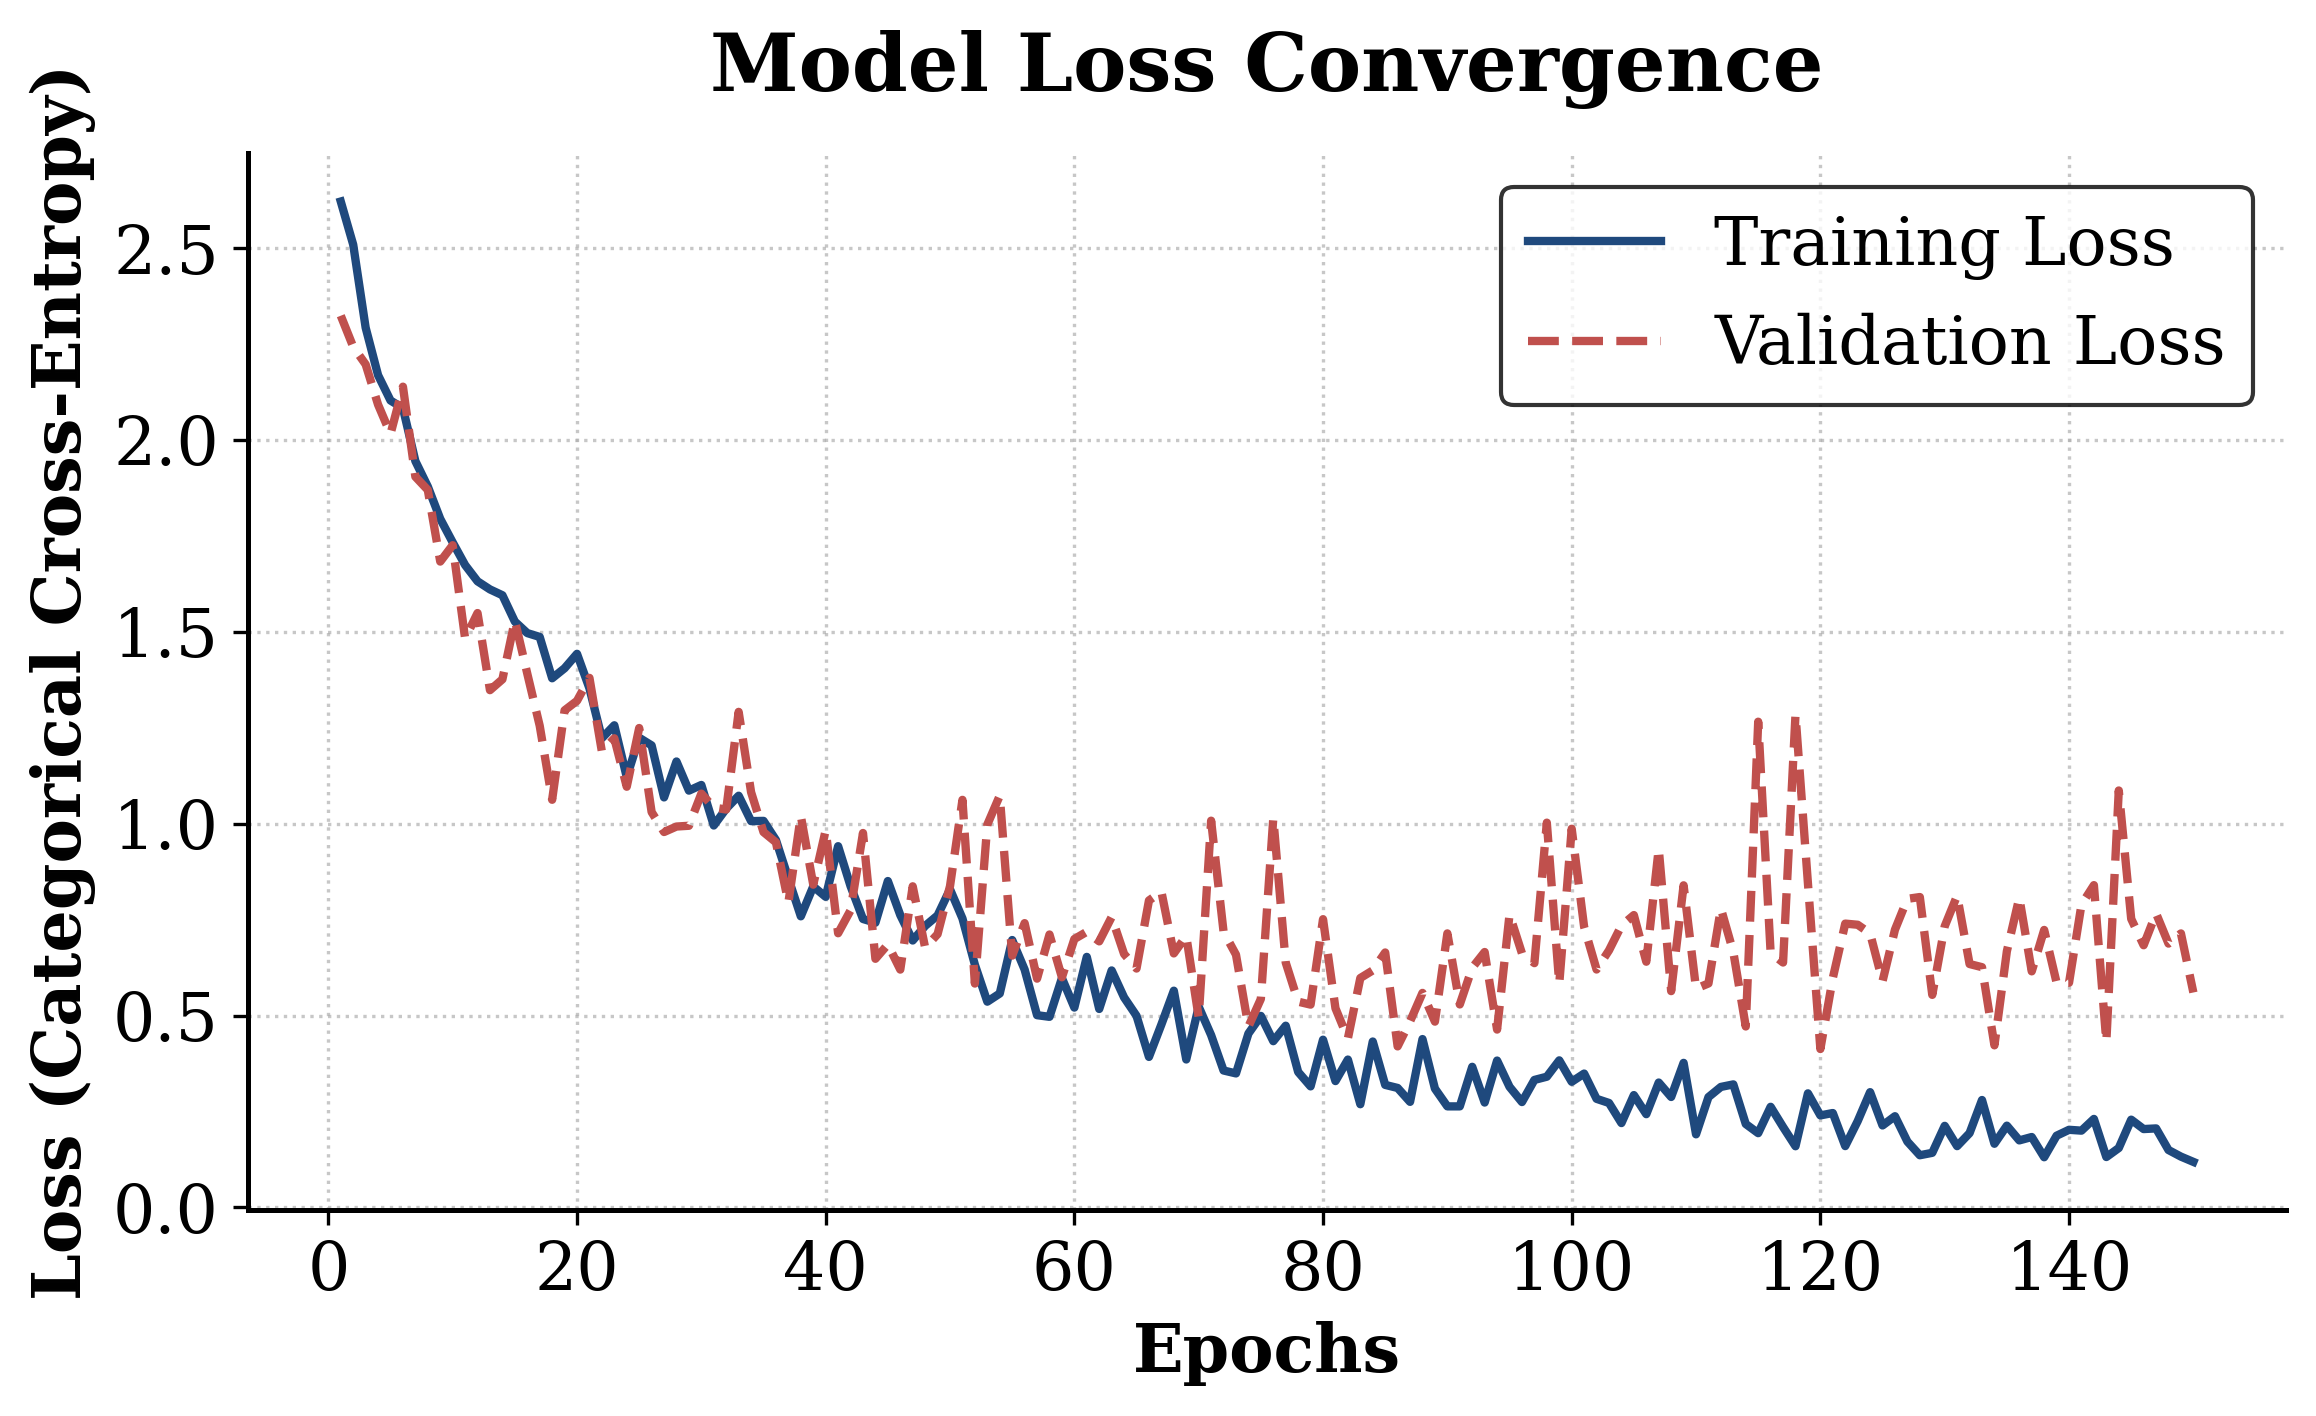

[SUCCESS] Flawless vector PDF and SVG graphics generated and saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import re

# 1. Raw training log data copied directly from your terminal output
log_data = """
Epoch 1/150 - loss: 2.6208 - sparse_categorical_accuracy: 0.1355 - val_loss: 2.3233 - val_sparse_categorical_accuracy: 0.2222
Epoch 2/150 - loss: 2.5084 - sparse_categorical_accuracy: 0.1387 - val_loss: 2.2422 - val_sparse_categorical_accuracy: 0.2037
Epoch 3/150 - loss: 2.2922 - sparse_categorical_accuracy: 0.2361 - val_loss: 2.1965 - val_sparse_categorical_accuracy: 0.2407
Epoch 4/150 - loss: 2.1683 - sparse_categorical_accuracy: 0.2373 - val_loss: 2.0915 - val_sparse_categorical_accuracy: 0.2407
Epoch 5/150 - loss: 2.1024 - sparse_categorical_accuracy: 0.3272 - val_loss: 2.0152 - val_sparse_categorical_accuracy: 0.2222
Epoch 6/150 - loss: 2.0824 - sparse_categorical_accuracy: 0.2665 - val_loss: 2.1384 - val_sparse_categorical_accuracy: 0.2963
Epoch 7/150 - loss: 1.9445 - sparse_categorical_accuracy: 0.3178 - val_loss: 1.9038 - val_sparse_categorical_accuracy: 0.3333
Epoch 8/150 - loss: 1.8782 - sparse_categorical_accuracy: 0.3064 - val_loss: 1.8693 - val_sparse_categorical_accuracy: 0.3148
Epoch 9/150 - loss: 1.7940 - sparse_categorical_accuracy: 0.3944 - val_loss: 1.6827 - val_sparse_categorical_accuracy: 0.3889
Epoch 10/150 - loss: 1.7329 - sparse_categorical_accuracy: 0.3747 - val_loss: 1.7254 - val_sparse_categorical_accuracy: 0.3704
Epoch 11/150 - loss: 1.6737 - sparse_categorical_accuracy: 0.3680 - val_loss: 1.4822 - val_sparse_categorical_accuracy: 0.5370
Epoch 12/150 - loss: 1.6313 - sparse_categorical_accuracy: 0.4171 - val_loss: 1.5486 - val_sparse_categorical_accuracy: 0.4259
Epoch 13/150 - loss: 1.6102 - sparse_categorical_accuracy: 0.4119 - val_loss: 1.3477 - val_sparse_categorical_accuracy: 0.5926
Epoch 14/150 - loss: 1.5950 - sparse_categorical_accuracy: 0.4177 - val_loss: 1.3760 - val_sparse_categorical_accuracy: 0.5185
Epoch 15/150 - loss: 1.5264 - sparse_categorical_accuracy: 0.4209 - val_loss: 1.5294 - val_sparse_categorical_accuracy: 0.3704
Epoch 16/150 - loss: 1.4964 - sparse_categorical_accuracy: 0.4605 - val_loss: 1.3908 - val_sparse_categorical_accuracy: 0.4074
Epoch 17/150 - loss: 1.4864 - sparse_categorical_accuracy: 0.4176 - val_loss: 1.2549 - val_sparse_categorical_accuracy: 0.5370
Epoch 18/150 - loss: 1.3787 - sparse_categorical_accuracy: 0.4949 - val_loss: 1.0621 - val_sparse_categorical_accuracy: 0.7037
Epoch 19/150 - loss: 1.4048 - sparse_categorical_accuracy: 0.5062 - val_loss: 1.2951 - val_sparse_categorical_accuracy: 0.5185
Epoch 20/150 - loss: 1.4424 - sparse_categorical_accuracy: 0.4516 - val_loss: 1.3199 - val_sparse_categorical_accuracy: 0.5000
Epoch 21/150 - loss: 1.3525 - sparse_categorical_accuracy: 0.5165 - val_loss: 1.3797 - val_sparse_categorical_accuracy: 0.4630
Epoch 22/150 - loss: 1.2226 - sparse_categorical_accuracy: 0.5714 - val_loss: 1.1877 - val_sparse_categorical_accuracy: 0.5926
Epoch 23/150 - loss: 1.2562 - sparse_categorical_accuracy: 0.5341 - val_loss: 1.2223 - val_sparse_categorical_accuracy: 0.5741
Epoch 24/150 - loss: 1.1211 - sparse_categorical_accuracy: 0.5956 - val_loss: 1.0961 - val_sparse_categorical_accuracy: 0.6111
Epoch 25/150 - loss: 1.2238 - sparse_categorical_accuracy: 0.6173 - val_loss: 1.2491 - val_sparse_categorical_accuracy: 0.5741
Epoch 26/150 - loss: 1.2038 - sparse_categorical_accuracy: 0.6026 - val_loss: 1.0302 - val_sparse_categorical_accuracy: 0.6111
Epoch 27/150 - loss: 1.0683 - sparse_categorical_accuracy: 0.6421 - val_loss: 0.9781 - val_sparse_categorical_accuracy: 0.6481
Epoch 28/150 - loss: 1.1619 - sparse_categorical_accuracy: 0.5760 - val_loss: 0.9924 - val_sparse_categorical_accuracy: 0.6481
Epoch 29/150 - loss: 1.0860 - sparse_categorical_accuracy: 0.6028 - val_loss: 0.9944 - val_sparse_categorical_accuracy: 0.6111
Epoch 30/150 - loss: 1.1007 - sparse_categorical_accuracy: 0.6336 - val_loss: 1.0782 - val_sparse_categorical_accuracy: 0.6111
Epoch 31/150 - loss: 0.9951 - sparse_categorical_accuracy: 0.6401 - val_loss: 1.0418 - val_sparse_categorical_accuracy: 0.6296
Epoch 32/150 - loss: 1.0391 - sparse_categorical_accuracy: 0.5941 - val_loss: 1.0367 - val_sparse_categorical_accuracy: 0.6667
Epoch 33/150 - loss: 1.0727 - sparse_categorical_accuracy: 0.6384 - val_loss: 1.2912 - val_sparse_categorical_accuracy: 0.5926
Epoch 34/150 - loss: 1.0065 - sparse_categorical_accuracy: 0.6479 - val_loss: 1.0820 - val_sparse_categorical_accuracy: 0.6296
Epoch 35/150 - loss: 1.0071 - sparse_categorical_accuracy: 0.6598 - val_loss: 0.9779 - val_sparse_categorical_accuracy: 0.6667
Epoch 36/150 - loss: 0.9572 - sparse_categorical_accuracy: 0.6850 - val_loss: 0.9513 - val_sparse_categorical_accuracy: 0.6296
Epoch 37/150 - loss: 0.8571 - sparse_categorical_accuracy: 0.6928 - val_loss: 0.7940 - val_sparse_categorical_accuracy: 0.6852
Epoch 38/150 - loss: 0.7585 - sparse_categorical_accuracy: 0.7287 - val_loss: 1.0203 - val_sparse_categorical_accuracy: 0.6111
Epoch 39/150 - loss: 0.8363 - sparse_categorical_accuracy: 0.6971 - val_loss: 0.8409 - val_sparse_categorical_accuracy: 0.7778
Epoch 40/150 - loss: 0.8093 - sparse_categorical_accuracy: 0.6989 - val_loss: 0.9829 - val_sparse_categorical_accuracy: 0.6667
Epoch 41/150 - loss: 0.9412 - sparse_categorical_accuracy: 0.6784 - val_loss: 0.7144 - val_sparse_categorical_accuracy: 0.7593
Epoch 42/150 - loss: 0.8372 - sparse_categorical_accuracy: 0.7096 - val_loss: 0.7740 - val_sparse_categorical_accuracy: 0.7963
Epoch 43/150 - loss: 0.7515 - sparse_categorical_accuracy: 0.7613 - val_loss: 0.9756 - val_sparse_categorical_accuracy: 0.7037
Epoch 44/150 - loss: 0.7419 - sparse_categorical_accuracy: 0.7375 - val_loss: 0.6478 - val_sparse_categorical_accuracy: 0.8333
Epoch 45/150 - loss: 0.8504 - sparse_categorical_accuracy: 0.7482 - val_loss: 0.6852 - val_sparse_categorical_accuracy: 0.7963
Epoch 46/150 - loss: 0.7617 - sparse_categorical_accuracy: 0.7327 - val_loss: 0.6197 - val_sparse_categorical_accuracy: 0.8519
Epoch 47/150 - loss: 0.6955 - sparse_categorical_accuracy: 0.7363 - val_loss: 0.8367 - val_sparse_categorical_accuracy: 0.7037
Epoch 48/150 - loss: 0.7335 - sparse_categorical_accuracy: 0.7404 - val_loss: 0.6766 - val_sparse_categorical_accuracy: 0.7407
Epoch 49/150 - loss: 0.7608 - sparse_categorical_accuracy: 0.7377 - val_loss: 0.7121 - val_sparse_categorical_accuracy: 0.7593
Epoch 50/150 - loss: 0.8288 - sparse_categorical_accuracy: 0.7359 - val_loss: 0.8371 - val_sparse_categorical_accuracy: 0.7963
Epoch 51/150 - loss: 0.7529 - sparse_categorical_accuracy: 0.7563 - val_loss: 1.0619 - val_sparse_categorical_accuracy: 0.6296
Epoch 52/150 - loss: 0.6322 - sparse_categorical_accuracy: 0.7814 - val_loss: 0.5833 - val_sparse_categorical_accuracy: 0.8519
Epoch 53/150 - loss: 0.5361 - sparse_categorical_accuracy: 0.8160 - val_loss: 0.9974 - val_sparse_categorical_accuracy: 0.7593
Epoch 54/150 - loss: 0.5574 - sparse_categorical_accuracy: 0.8169 - val_loss: 1.0728 - val_sparse_categorical_accuracy: 0.7037
Epoch 55/150 - loss: 0.6967 - sparse_categorical_accuracy: 0.7769 - val_loss: 0.6561 - val_sparse_categorical_accuracy: 0.8148
Epoch 56/150 - loss: 0.6198 - sparse_categorical_accuracy: 0.7991 - val_loss: 0.7407 - val_sparse_categorical_accuracy: 0.7407
Epoch 57/150 - loss: 0.5009 - sparse_categorical_accuracy: 0.8527 - val_loss: 0.5961 - val_sparse_categorical_accuracy: 0.7963
Epoch 58/150 - loss: 0.4966 - sparse_categorical_accuracy: 0.8412 - val_loss: 0.7111 - val_sparse_categorical_accuracy: 0.7222
Epoch 59/150 - loss: 0.5974 - sparse_categorical_accuracy: 0.7732 - val_loss: 0.5996 - val_sparse_categorical_accuracy: 0.8704
Epoch 60/150 - loss: 0.5207 - sparse_categorical_accuracy: 0.8054 - val_loss: 0.6993 - val_sparse_categorical_accuracy: 0.7963
Epoch 61/150 - loss: 0.6528 - sparse_categorical_accuracy: 0.7933 - val_loss: 0.7182 - val_sparse_categorical_accuracy: 0.7963
Epoch 62/150 - loss: 0.5171 - sparse_categorical_accuracy: 0.8195 - val_loss: 0.6932 - val_sparse_categorical_accuracy: 0.7778
Epoch 63/150 - loss: 0.6175 - sparse_categorical_accuracy: 0.7861 - val_loss: 0.7567 - val_sparse_categorical_accuracy: 0.8148
Epoch 64/150 - loss: 0.5471 - sparse_categorical_accuracy: 0.8283 - val_loss: 0.6603 - val_sparse_categorical_accuracy: 0.8148
Epoch 65/150 - loss: 0.4992 - sparse_categorical_accuracy: 0.8292 - val_loss: 0.6224 - val_sparse_categorical_accuracy: 0.8148
Epoch 66/150 - loss: 0.3922 - sparse_categorical_accuracy: 0.8899 - val_loss: 0.7998 - val_sparse_categorical_accuracy: 0.8333
Epoch 67/150 - loss: 0.4767 - sparse_categorical_accuracy: 0.8322 - val_loss: 0.8228 - val_sparse_categorical_accuracy: 0.7778
Epoch 68/150 - loss: 0.5647 - sparse_categorical_accuracy: 0.8205 - val_loss: 0.6618 - val_sparse_categorical_accuracy: 0.8333
Epoch 69/150 - loss: 0.3855 - sparse_categorical_accuracy: 0.8945 - val_loss: 0.7074 - val_sparse_categorical_accuracy: 0.8333
Epoch 70/150 - loss: 0.5230 - sparse_categorical_accuracy: 0.8415 - val_loss: 0.4950 - val_sparse_categorical_accuracy: 0.8889
Epoch 71/150 - loss: 0.4489 - sparse_categorical_accuracy: 0.8552 - val_loss: 1.0076 - val_sparse_categorical_accuracy: 0.7222
Epoch 72/150 - loss: 0.3568 - sparse_categorical_accuracy: 0.8965 - val_loss: 0.7183 - val_sparse_categorical_accuracy: 0.7963
Epoch 73/150 - loss: 0.3492 - sparse_categorical_accuracy: 0.8887 - val_loss: 0.6585 - val_sparse_categorical_accuracy: 0.8519
Epoch 74/150 - loss: 0.4531 - sparse_categorical_accuracy: 0.8539 - val_loss: 0.4711 - val_sparse_categorical_accuracy: 0.8704
Epoch 75/150 - loss: 0.4990 - sparse_categorical_accuracy: 0.8238 - val_loss: 0.5432 - val_sparse_categorical_accuracy: 0.8519
Epoch 76/150 - loss: 0.4332 - sparse_categorical_accuracy: 0.8309 - val_loss: 1.0144 - val_sparse_categorical_accuracy: 0.6852
Epoch 77/150 - loss: 0.4735 - sparse_categorical_accuracy: 0.8579 - val_loss: 0.6380 - val_sparse_categorical_accuracy: 0.8519
Epoch 78/150 - loss: 0.3529 - sparse_categorical_accuracy: 0.8833 - val_loss: 0.5361 - val_sparse_categorical_accuracy: 0.8704
Epoch 79/150 - loss: 0.3154 - sparse_categorical_accuracy: 0.9242 - val_loss: 0.5284 - val_sparse_categorical_accuracy: 0.8704
Epoch 80/150 - loss: 0.4370 - sparse_categorical_accuracy: 0.8735 - val_loss: 0.7510 - val_sparse_categorical_accuracy: 0.8519
Epoch 81/150 - loss: 0.3292 - sparse_categorical_accuracy: 0.8948 - val_loss: 0.5189 - val_sparse_categorical_accuracy: 0.8889
Epoch 82/150 - loss: 0.3853 - sparse_categorical_accuracy: 0.8908 - val_loss: 0.4402 - val_sparse_categorical_accuracy: 0.8519
Epoch 83/150 - loss: 0.2689 - sparse_categorical_accuracy: 0.9262 - val_loss: 0.5977 - val_sparse_categorical_accuracy: 0.8704
Epoch 84/150 - loss: 0.4323 - sparse_categorical_accuracy: 0.8418 - val_loss: 0.6176 - val_sparse_categorical_accuracy: 0.8333
Epoch 85/150 - loss: 0.3193 - sparse_categorical_accuracy: 0.9188 - val_loss: 0.6643 - val_sparse_categorical_accuracy: 0.7963
Epoch 86/150 - loss: 0.3113 - sparse_categorical_accuracy: 0.9028 - val_loss: 0.4196 - val_sparse_categorical_accuracy: 0.9259
Epoch 87/150 - loss: 0.2751 - sparse_categorical_accuracy: 0.9220 - val_loss: 0.4846 - val_sparse_categorical_accuracy: 0.9074
Epoch 88/150 - loss: 0.4387 - sparse_categorical_accuracy: 0.8941 - val_loss: 0.5590 - val_sparse_categorical_accuracy: 0.8333
Epoch 89/150 - loss: 0.3096 - sparse_categorical_accuracy: 0.9175 - val_loss: 0.4841 - val_sparse_categorical_accuracy: 0.8519
Epoch 90/150 - loss: 0.2633 - sparse_categorical_accuracy: 0.9231 - val_loss: 0.7140 - val_sparse_categorical_accuracy: 0.8519
Epoch 91/150 - loss: 0.2633 - sparse_categorical_accuracy: 0.9099 - val_loss: 0.5289 - val_sparse_categorical_accuracy: 0.8704
Epoch 92/150 - loss: 0.3664 - sparse_categorical_accuracy: 0.8841 - val_loss: 0.6246 - val_sparse_categorical_accuracy: 0.8519
Epoch 93/150 - loss: 0.2733 - sparse_categorical_accuracy: 0.9193 - val_loss: 0.6655 - val_sparse_categorical_accuracy: 0.8519
Epoch 94/150 - loss: 0.3827 - sparse_categorical_accuracy: 0.8604 - val_loss: 0.4634 - val_sparse_categorical_accuracy: 0.8704
Epoch 95/150 - loss: 0.3143 - sparse_categorical_accuracy: 0.9186 - val_loss: 0.7632 - val_sparse_categorical_accuracy: 0.8148
Epoch 96/150 - loss: 0.2746 - sparse_categorical_accuracy: 0.9158 - val_loss: 0.6619 - val_sparse_categorical_accuracy: 0.7778
Epoch 97/150 - loss: 0.3322 - sparse_categorical_accuracy: 0.8865 - val_loss: 0.6365 - val_sparse_categorical_accuracy: 0.8148
Epoch 98/150 - loss: 0.3406 - sparse_categorical_accuracy: 0.8966 - val_loss: 1.0025 - val_sparse_categorical_accuracy: 0.7593
Epoch 99/150 - loss: 0.3832 - sparse_categorical_accuracy: 0.8782 - val_loss: 0.5829 - val_sparse_categorical_accuracy: 0.8519
Epoch 100/150 - loss: 0.3274 - sparse_categorical_accuracy: 0.8970 - val_loss: 0.9866 - val_sparse_categorical_accuracy: 0.7593
Epoch 101/150 - loss: 0.3488 - sparse_categorical_accuracy: 0.9158 - val_loss: 0.7311 - val_sparse_categorical_accuracy: 0.8148
Epoch 102/150 - loss: 0.2830 - sparse_categorical_accuracy: 0.9225 - val_loss: 0.6199 - val_sparse_categorical_accuracy: 0.8704
Epoch 103/150 - loss: 0.2722 - sparse_categorical_accuracy: 0.8988 - val_loss: 0.6698 - val_sparse_categorical_accuracy: 0.8519
Epoch 104/150 - loss: 0.2198 - sparse_categorical_accuracy: 0.9204 - val_loss: 0.7344 - val_sparse_categorical_accuracy: 0.7963
Epoch 105/150 - loss: 0.2927 - sparse_categorical_accuracy: 0.9124 - val_loss: 0.7617 - val_sparse_categorical_accuracy: 0.8148
Epoch 106/150 - loss: 0.2430 - sparse_categorical_accuracy: 0.9070 - val_loss: 0.6402 - val_sparse_categorical_accuracy: 0.8519
Epoch 107/150 - loss: 0.3254 - sparse_categorical_accuracy: 0.8917 - val_loss: 0.9352 - val_sparse_categorical_accuracy: 0.7593
Epoch 108/150 - loss: 0.2878 - sparse_categorical_accuracy: 0.8990 - val_loss: 0.5636 - val_sparse_categorical_accuracy: 0.8889
Epoch 109/150 - loss: 0.3767 - sparse_categorical_accuracy: 0.9242 - val_loss: 0.8392 - val_sparse_categorical_accuracy: 0.8333
Epoch 110/150 - loss: 0.1905 - sparse_categorical_accuracy: 0.9429 - val_loss: 0.5701 - val_sparse_categorical_accuracy: 0.8704
Epoch 111/150 - loss: 0.2875 - sparse_categorical_accuracy: 0.9108 - val_loss: 0.5836 - val_sparse_categorical_accuracy: 0.8889
Epoch 112/150 - loss: 0.3140 - sparse_categorical_accuracy: 0.9123 - val_loss: 0.7788 - val_sparse_categorical_accuracy: 0.7963
Epoch 113/150 - loss: 0.3206 - sparse_categorical_accuracy: 0.9197 - val_loss: 0.6653 - val_sparse_categorical_accuracy: 0.8148
Epoch 114/150 - loss: 0.2174 - sparse_categorical_accuracy: 0.9259 - val_loss: 0.4715 - val_sparse_categorical_accuracy: 0.9074
Epoch 115/150 - loss: 0.1935 - sparse_categorical_accuracy: 0.9435 - val_loss: 1.2655 - val_sparse_categorical_accuracy: 0.7593
Epoch 116/150 - loss: 0.2622 - sparse_categorical_accuracy: 0.9214 - val_loss: 0.6635 - val_sparse_categorical_accuracy: 0.8704
Epoch 117/150 - loss: 0.2096 - sparse_categorical_accuracy: 0.9401 - val_loss: 0.6381 - val_sparse_categorical_accuracy: 0.8704
Epoch 118/150 - loss: 0.1594 - sparse_categorical_accuracy: 0.9619 - val_loss: 1.2843 - val_sparse_categorical_accuracy: 0.7407
Epoch 119/150 - loss: 0.2973 - sparse_categorical_accuracy: 0.9016 - val_loss: 0.8445 - val_sparse_categorical_accuracy: 0.7778
Epoch 120/150 - loss: 0.2398 - sparse_categorical_accuracy: 0.9078 - val_loss: 0.4127 - val_sparse_categorical_accuracy: 0.8889
Epoch 121/150 - loss: 0.2460 - sparse_categorical_accuracy: 0.9442 - val_loss: 0.5974 - val_sparse_categorical_accuracy: 0.8148
Epoch 122/150 - loss: 0.1598 - sparse_categorical_accuracy: 0.9542 - val_loss: 0.7395 - val_sparse_categorical_accuracy: 0.7963
Epoch 123/150 - loss: 0.2247 - sparse_categorical_accuracy: 0.9214 - val_loss: 0.7365 - val_sparse_categorical_accuracy: 0.8333
Epoch 124/150 - loss: 0.3004 - sparse_categorical_accuracy: 0.9104 - val_loss: 0.7141 - val_sparse_categorical_accuracy: 0.8704
Epoch 125/150 - loss: 0.2136 - sparse_categorical_accuracy: 0.9315 - val_loss: 0.5894 - val_sparse_categorical_accuracy: 0.8519
Epoch 126/150 - loss: 0.2377 - sparse_categorical_accuracy: 0.9359 - val_loss: 0.7237 - val_sparse_categorical_accuracy: 0.8519
Epoch 127/150 - loss: 0.1716 - sparse_categorical_accuracy: 0.9386 - val_loss: 0.8040 - val_sparse_categorical_accuracy: 0.8519
Epoch 128/150 - loss: 0.1360 - sparse_categorical_accuracy: 0.9558 - val_loss: 0.8087 - val_sparse_categorical_accuracy: 0.8333
Epoch 129/150 - loss: 0.1423 - sparse_categorical_accuracy: 0.9480 - val_loss: 0.5538 - val_sparse_categorical_accuracy: 0.8704
Epoch 130/150 - loss: 0.2126 - sparse_categorical_accuracy: 0.9489 - val_loss: 0.7325 - val_sparse_categorical_accuracy: 0.8704
Epoch 131/150 - loss: 0.1597 - sparse_categorical_accuracy: 0.9611 - val_loss: 0.8125 - val_sparse_categorical_accuracy: 0.8148
Epoch 132/150 - loss: 0.1936 - sparse_categorical_accuracy: 0.9585 - val_loss: 0.6342 - val_sparse_categorical_accuracy: 0.8519
Epoch 133/150 - loss: 0.2799 - sparse_categorical_accuracy: 0.9178 - val_loss: 0.6260 - val_sparse_categorical_accuracy: 0.8704
Epoch 134/150 - loss: 0.1659 - sparse_categorical_accuracy: 0.9429 - val_loss: 0.4223 - val_sparse_categorical_accuracy: 0.8889
Epoch 135/150 - loss: 0.2131 - sparse_categorical_accuracy: 0.9341 - val_loss: 0.6675 - val_sparse_categorical_accuracy: 0.8519
Epoch 136/150 - loss: 0.1747 - sparse_categorical_accuracy: 0.9428 - val_loss: 0.8071 - val_sparse_categorical_accuracy: 0.8519
Epoch 137/150 - loss: 0.1835 - sparse_categorical_accuracy: 0.9598 - val_loss: 0.6151 - val_sparse_categorical_accuracy: 0.8519
Epoch 138/150 - loss: 0.1308 - sparse_categorical_accuracy: 0.9781 - val_loss: 0.7230 - val_sparse_categorical_accuracy: 0.8704
Epoch 139/150 - loss: 0.1869 - sparse_categorical_accuracy: 0.9522 - val_loss: 0.5856 - val_sparse_categorical_accuracy: 0.8704
Epoch 140/150 - loss: 0.2023 - sparse_categorical_accuracy: 0.9363 - val_loss: 0.5853 - val_sparse_categorical_accuracy: 0.8704
Epoch 141/150 - loss: 0.2001 - sparse_categorical_accuracy: 0.9337 - val_loss: 0.7891 - val_sparse_categorical_accuracy: 0.8519
Epoch 142/150 - loss: 0.2306 - sparse_categorical_accuracy: 0.9194 - val_loss: 0.8397 - val_sparse_categorical_accuracy: 0.8704
Epoch 143/150 - loss: 0.1313 - sparse_categorical_accuracy: 0.9663 - val_loss: 0.4314 - val_sparse_categorical_accuracy: 0.9074
Epoch 144/150 - loss: 0.1548 - sparse_categorical_accuracy: 0.9433 - val_loss: 1.0863 - val_sparse_categorical_accuracy: 0.8333
Epoch 145/150 - loss: 0.2287 - sparse_categorical_accuracy: 0.9350 - val_loss: 0.7518 - val_sparse_categorical_accuracy: 0.8704
Epoch 146/150 - loss: 0.2042 - sparse_categorical_accuracy: 0.9373 - val_loss: 0.6831 - val_sparse_categorical_accuracy: 0.8333
Epoch 147/150 - loss: 0.2059 - sparse_categorical_accuracy: 0.9331 - val_loss: 0.7662 - val_sparse_categorical_accuracy: 0.7963
Epoch 148/150 - loss: 0.1496 - sparse_categorical_accuracy: 0.9582 - val_loss: 0.6874 - val_sparse_categorical_accuracy: 0.8519
Epoch 149/150 - loss: 0.1324 - sparse_categorical_accuracy: 0.9742 - val_loss: 0.7139 - val_sparse_categorical_accuracy: 0.8148
Epoch 150/150 - loss: 0.1187 - sparse_categorical_accuracy: 0.9602 - val_loss: 0.5600 - val_sparse_categorical_accuracy: 0.8519
"""

# 2. Parse out the metrics automatically using regex expressions
epochs, loss, acc, val_loss, val_acc = [], [], [], [], []

pattern = re.compile(
    r"Epoch\s+(\d+).*?- loss:\s+([\d\.]+)\s+- sparse_categorical_accuracy:\s+([\d\.]+)\s+- val_loss:\s+([\d\.]+)\s+- val_sparse_categorical_accuracy:\s+([\d\.]+)"
)

for line in log_data.strip().split('\n'):
    match = pattern.search(line)
    if match:
        epochs.append(int(match.group(1)))
        loss.append(float(match.group(2)))
        acc.append(float(match.group(3)))
        val_loss.append(float(match.group(4)))
        val_acc.append(float(match.group(5)))

# --- PREMIUM STYLING CONFIGURATION ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 16
plt.rcParams['axes.linewidth'] = 1.2

# 3. Create standalone, clean visual architectures for each graph
# Plot 1: Model Accuracy Convergence
fig1, ax1 = plt.subplots(figsize=(8, 5), dpi=300)
ax1.plot(epochs, acc, label='Training Accuracy', color='#1f497d', linewidth=2)
ax1.plot(epochs, val_acc, label='Validation Accuracy', color='#c0504d', linewidth=2, linestyle='--')
ax1.set_title('Model Accuracy Convergence', fontweight='bold', pad=15)
ax1.set_xlabel('Epochs', fontweight='bold')
ax1.set_ylabel('Accuracy', fontweight='bold')
ax1.legend(loc='lower right', frameon=True, edgecolor='black')
ax1.grid(True, linestyle=':', alpha=0.7, color='#b0b0b0')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('Model_Accuracy_Convergence.pdf', format='pdf', bbox_inches='tight')
plt.savefig('Model_Accuracy_Convergence.svg', format='svg', bbox_inches='tight')
plt.show()

# Plot 2: Model Loss Convergence
fig2, ax2 = plt.subplots(figsize=(8, 5), dpi=300)
ax2.plot(epochs, loss, label='Training Loss', color='#1f497d', linewidth=2)
ax2.plot(epochs, val_loss, label='Validation Loss', color='#c0504d', linewidth=2, linestyle='--')
ax2.set_title('Model Loss Convergence', fontweight='bold', pad=15)
ax2.set_xlabel('Epochs', fontweight='bold')
ax2.set_ylabel('Loss (Categorical Cross-Entropy)', fontweight='bold')
ax2.legend(loc='upper right', frameon=True, edgecolor='black')
ax2.grid(True, linestyle=':', alpha=0.7, color='#b0b0b0')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('Model_Loss_Convergence.pdf', format='pdf', bbox_inches='tight')
plt.savefig('Model_Loss_Convergence.svg', format='svg', bbox_inches='tight')
plt.show()

print("[SUCCESS] Flawless vector PDF and SVG graphics generated and saved successfully!")